# RQ05 — Frequência de deploy e taxa de falha (#170)

**Repositórios com maior frequência de deploy apresentam maior ou menor taxa de falha?**

Analisamos separadamente DF × CFR (a), baseada em runs de CI, e DF × CFR (b), baseada em releases corretivas. A unidade é o repositório; o CSV final é a única entrada de dados. As funções estão em `pipeline/correlacao_rq05.py`.

A hipótese registrada antes desta análise previa associação negativa. O notebook calcula e mostra os resultados observados, sem converter associação em causalidade.

## Reprodução e parâmetros

Instale `requirements.txt` e execute todas as células, a partir de `Lab03/` ou `Lab03/analise/`. Não são necessários token, API ou JSONs de coleta. Para outro CSV do mesmo contrato, defina `LAB03_RQ05_CSV`; para uma saída isolada, defina `LAB03_RQ05_SAIDA` antes de iniciar o kernel. Caminhos relativos dessas variáveis são resolvidos a partir da pasta de trabalho.

Os resultados usam `scipy.stats.spearmanr`, teste bilateral e ranks médios para empates. O p-valor assintótico solicitado pelo enunciado é `p_valor`. Como a documentação do SciPy ressalva sua precisão com até 500 observações, também reportamos `p_permutacao`, bilateral, com **99.999 permutações de pareamentos e semente 170**. Só a CFR é permutada; os ranks e empates são preservados. O SciPy inclui a observação no cálculo aleatório (+1 no numerador e denominador) e dobra a menor cauda. A resolução mínima bilateral aleatória nesta configuração é 0,00002, não zero. Amostras pequenas com todas as permutações enumeradas usam o teste exato.

Referências: [Spearman no SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html) e [teste de permutação](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).

In [1]:
import hashlib
import json
import os
import platform
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import Markdown, display

candidatas = [p / sufixo for p in (Path.cwd(), *Path.cwd().parents) for sufixo in ("", "Lab03")]
RAIZ = next(p for p in candidatas if (p / "pipeline/correlacao_rq05.py").is_file())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
from pipeline.correlacao_rq05 import (PERMUTACOES, SEMENTE, analisar, carregar_dataset, grafico_dispersao)

DATASET = Path(os.environ.get("LAB03_RQ05_CSV", str(RAIZ / "entregas/s02-03-dataset-500-final/dataset-500.csv"))).expanduser().resolve()
SAIDA = Path(os.environ.get("LAB03_RQ05_SAIDA", str(RAIZ / "analise"))).expanduser().resolve()
FIGURAS, TABELAS = SAIDA / "figuras", SAIDA / "tabelas"
destinos = {TABELAS / nome for nome in ("rq05_spearman.csv", "rq05_pares.csv", "rq05_exclusoes.csv", "rq05_proveniencia.json")}
destinos.add(FIGURAS / "rq05_df_cfr_spearman.png")
if DATASET in {p.resolve() for p in destinos}:
    raise ValueError("Saída não pode sobrescrever o CSV de entrada.")
FIGURAS.mkdir(parents=True, exist_ok=True)
TABELAS.mkdir(parents=True, exist_ok=True)

dados = carregar_dataset(DATASET)
sha_entrada = dados.attrs["csv_sha256"]
pd.options.display.float_format = "{:.6g}".format
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300, "font.size": 9})
display(pd.DataFrame({
    "metrica": ["deployment_frequency", "cfr_a", "cfr_b"],
    "unidade": ["releases/semana", "fração de runs", "fração de releases"],
    "validos": [dados[c].notna().sum() for c in ("deployment_frequency", "cfr_a", "cfr_b")],
    "ausentes": [dados[c].isna().sum() for c in ("deployment_frequency", "cfr_a", "cfr_b")],
}))
print(f"Repositórios: {len(dados)} | SHA-256 do CSV: {sha_entrada}")

Matplotlib is building the font cache; this may take a moment.


,metrica,unidade,validos,ausentes
0,deployment_frequency,releases/semana,500,0
1,cfr_a,fração de runs,500,0
2,cfr_b,fração de releases,498,2


Repositórios: 500 | SHA-256 do CSV: 2552ba6b0779e895d01bea88742cb668ee1812a8369a224ed5281708140b30bd


## Pares e exclusões

A análise principal mantém todos os valores disponíveis por par: um nulo em CFR (b) não elimina um repositório de DF × CFR (a). Zeros observados continuam zero. Não há imputação, remoção de outliers ou transformação para calcular rho; a escala logarítmica é apenas visual. IDs duplicados, janelas divergentes, infinitos, textos numéricos inválidos e valores fora do domínio são recusados.

Os indicadores globais `coleta_incompleta` e `calculo_parcial` não informam qual métrica foi afetada. Por isso, sua exclusão define uma **sensibilidade separada**, sem substituir a análise principal. Seu nome `sem_indicadores` significa apenas ausência dessas marcações; não comprova ausência de todos os problemas das fontes.

In [2]:
resumo, pares = analisar(dados, permutacoes=PERMUTACOES, semente=SEMENTE)
principal = resumo.loc[resumo["recorte"] == "principal"].copy()
colunas = ["variante", "n_universo", "n", "excluidos_por_nulos", "rho", "p_valor", "p_permutacao", "motivo"]
display(principal[colunas])

exclusoes = []
for variante in ("a", "b"):
    col_cfr = f"cfr_{variante}"
    for _, linha in dados.loc[dados[["deployment_frequency", col_cfr]].isna().any(axis=1)].iterrows():
        exclusoes.append({"id": linha["id"], "full_name": linha["full_name"], "variante": variante,
                          "metricas_ausentes_no_par": ";".join(c for c in ("deployment_frequency", col_cfr) if pd.isna(linha[c]))})
exclusoes = pd.DataFrame(exclusoes, columns=["id", "full_name", "variante", "metricas_ausentes_no_par"])
display(exclusoes)
print("Os pares sem dados ficam fora da correlação, sem receber valores artificiais.")

,variante,n_universo,n,excluidos_por_nulos,rho,p_valor,p_permutacao,motivo
0,a,500,500,0,0.154562,0.000523733,0.00054,None
1,b,500,498,2,0.799098,1.10854e-111,2e-05,None


,id,full_name,variante,metricas_ausentes_no_par
0,65750241,expo/expo,b,cfr_b
1,1144520675,Alishahryar1/free-claude-code,b,cfr_b


Os pares sem dados ficam fora da correlação, sem receber valores artificiais.


## Dispersão

Cada ponto representa um par efetivamente usado na análise principal. A DF do CSV final abrange mais de duas ordens de grandeza, então o eixo horizontal usa log. O eixo vertical é linear e mostra toda a faixa de CFR, incluindo zero e um. Em outro CSV com DF=0, a função usa `symlog` (trecho linear com limiar 0,1), mantendo os zeros visíveis. Não há jitter nem linha de regressão. Sobreposição de pontos é possível; n é o total de pares, não o número de marcas visíveis.

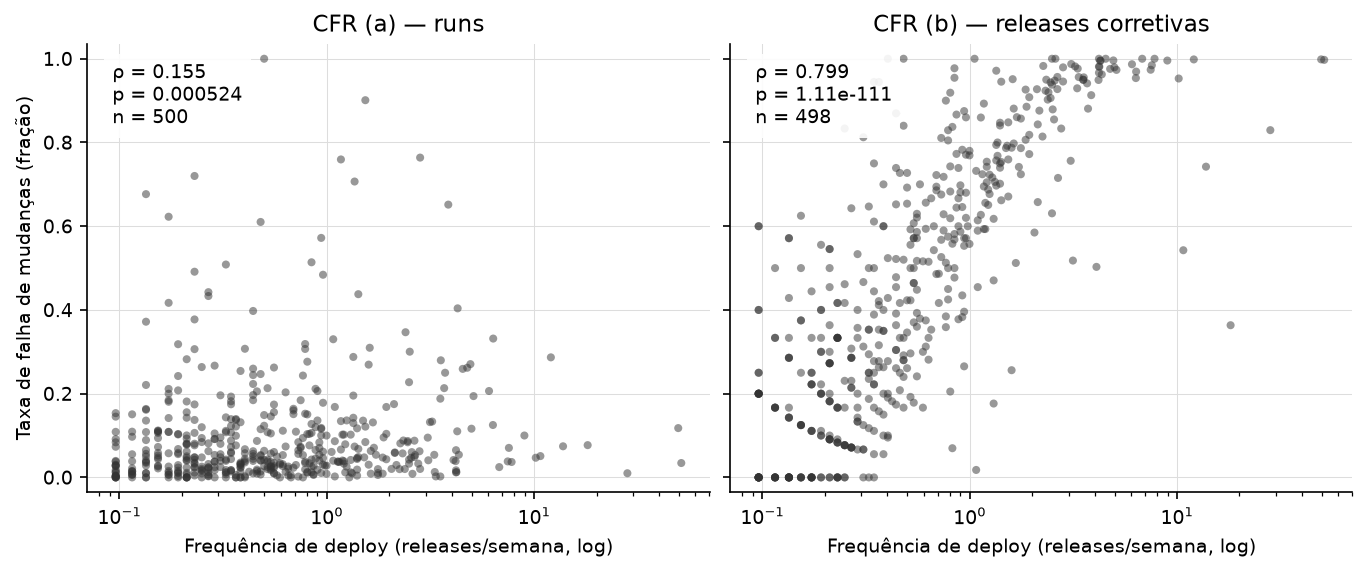

In [3]:
fig = grafico_dispersao(pares, resumo)
fig.savefig(FIGURAS / "rq05_df_cfr_spearman.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

## Sensibilidade aos indicadores de dados incompletos

Abaixo, retiramos os repositórios que possuem pelo menos um dos dois indicadores e repetimos o mesmo procedimento. A filtragem continua por par dentro desse recorte. `fora_do_recorte` conta as exclusões pelos indicadores; `excluidos_por_nulos` conta os nulos restantes. Poucos pares (n<3) ou variável constante produzem valores não estimáveis, com motivo explícito; correlação indefinida não vira zero.

In [4]:
sensibilidade = resumo.loc[resumo["recorte"] == "sem_indicadores"]
display(sensibilidade[["variante", "n_universo", "fora_do_recorte", "n", "excluidos_por_nulos", "rho", "p_valor", "p_permutacao", "motivo"]])

,variante,n_universo,fora_do_recorte,n,excluidos_por_nulos,rho,p_valor,p_permutacao,motivo
2,a,446,54,446,0,0.115381,0.0147687,0.01544,None
3,b,446,54,444,2,0.777516,4.46218e-91,2e-05,None


## Leitura dos resultados e limites

A tabela e a leitura abaixo são recalculadas a cada execução. Os dois testes principais são bilaterais e seus p-valores são apresentados **sem ajuste de multiplicidade**. Não se compara a diferença entre os dois rhos como se ela tivesse sido formalmente testada; as definições de CFR e os conjuntos de pares diferem. Rho mede a associação monotônica e sua magnitude; p-valor não mede a importância prática nem a probabilidade de uma hipótese ser verdadeira.

In [5]:
linhas = []
for _, r in principal.iterrows():
    if pd.isna(r["rho"]):
        linhas.append(f"- CFR ({r['variante']}): associação não estimável ({r['motivo']}); n={int(r['n'])}.")
    else:
        sentido = "positiva" if r["rho"] > 0 else "negativa" if r["rho"] < 0 else "nula em postos"
        linhas.append(f"- CFR ({r['variante']}): associação {sentido}, rho={r['rho']:.6f}, "
                      f"p assintótico={r['p_valor']:.6g}, p de permutação={r['p_permutacao']:.6g}, n={int(r['n'])}.")
display(Markdown("\n".join(linhas)))

- CFR (a): associação positiva, rho=0.154562, p assintótico=0.000523733, p de permutação=0.00054, n=500.
- CFR (b): associação positiva, rho=0.799098, p assintótico=1.10854e-111, p de permutação=2e-05, n=498.

No CSV final versionado, ambas as associações são positivas, contrariando a direção negativa esperada na hipótese local. O rho de CFR (b) é maior nesse recorte. Isso descreve os dados e as definições operacionais; não demonstra que publicar mais causa falhas, nem uma refutação geral do DORA. Comparações entre repositórios podem refletir tipo, maturidade e práticas distintas.

CFR (a) mede falhas de CI; elas não são necessariamente incidentes em produção. CFR (b) marca falha pela existência de uma corretiva em até sete dias: maior frequência gera mais oportunidades de observar uma release posterior nessa janela. Essa relação entre as definições pode contribuir para a associação, além de diferenças reais entre projetos. A validação humana completa da heurística ainda está pendente nas #162/#163; os resultados de CFR (b) devem ser lidos com essa limitação. O CSV agregado permite esta RQ05, mas não resolve as previsões ausentes da validação manual.

Esta leitura específica se refere ao CSV final de 500 repositórios. Se trocar `LAB03_RQ05_CSV`, revise este parágrafo após conferir os novos resultados. A seção de resultados do artigo pertence à #177.

## Exportação e proveniência

São gravados o resumo com precisão numérica completa, os pares usados em cada recorte, as exclusões principais por nulo, a figura e um JSON com hashes, janela, parâmetros e versões. O CSV de entrada é conferido novamente antes da exportação e permanece intacto.

In [6]:
if hashlib.sha256(DATASET.read_bytes()).hexdigest() != sha_entrada:
    raise RuntimeError("CSV de entrada mudou durante a análise; reexecute desde o início.")
resumo.to_csv(TABELAS / "rq05_spearman.csv", index=False, float_format="%.17g", lineterminator="\n")
pares.to_csv(TABELAS / "rq05_pares.csv", index=False, float_format="%.17g", lineterminator="\n")
exclusoes.to_csv(TABELAS / "rq05_exclusoes.csv", index=False, lineterminator="\n")

proveniencia = {
    "issue": 170,
    "csv": DATASET.relative_to(RAIZ).as_posix() if DATASET.is_relative_to(RAIZ) else str(DATASET),
    "csv_sha256": sha_entrada,
    "total_repositorios": len(dados),
    "janela": {"inicio": dados["janela_inicio"].iloc[0], "fim_exclusivo": dados["janela_fim_exclusivo"].iloc[0]},
    "unidade_analise": "repositório; DF em releases/semana; CFR em fração",
    "metodo": "scipy.stats.spearmanr; bilateral; empates por ranks médios; p_valor assintótico sem ajuste",
    "permutacao": {"tipo": "pairings", "variavel_permutada": "ranks de CFR", "alternativa": "two-sided",
                   "n_resamples": PERMUTACOES, "semente": SEMENTE, "rng": "numpy.default_rng (PCG64)",
                   "p_bilateral": "duas vezes a menor cauda; ajuste +1 em Monte Carlo; teste exato quando enumerável"},
    "sensibilidade": "exclui coleta_incompleta OU calculo_parcial; não substitui a análise principal",
    "codigo_sha256": hashlib.sha256((RAIZ / "pipeline/correlacao_rq05.py").read_bytes()).hexdigest(),
    "bibliotecas": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                    "scipy": scipy.__version__, "matplotlib": matplotlib.__version__},
}
(TABELAS / "rq05_proveniencia.json").write_text(json.dumps(proveniencia, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Exportados: rq05_spearman.csv, rq05_pares.csv, rq05_exclusoes.csv, rq05_proveniencia.json e rq05_df_cfr_spearman.png.")

Exportados: rq05_spearman.csv, rq05_pares.csv, rq05_exclusoes.csv, rq05_proveniencia.json e rq05_df_cfr_spearman.png.
